In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import KFold, cross_val_score

## Regression - Facebook page dataset

https://archive.ics.uci.edu/dataset/368/facebook+metrics 

In [24]:
#loading the dataset
reg_small = pd.read_csv("data_lab1/facebook+metrics/dataset_Facebook.csv", sep = ";")
reg_small

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,85093,Photo,3,1,7,2,0.0,4684,7536,733,708,985,4750,2876,392,5,53.0,26.0,84
496,81370,Photo,2,1,5,8,0.0,3480,6229,537,508,687,3961,2104,301,0,53.0,22.0,75
497,81370,Photo,1,1,5,2,0.0,3778,7216,625,572,795,4742,2388,363,4,93.0,18.0,115
498,81370,Photo,3,1,4,11,0.0,4156,7564,626,574,832,4534,2452,370,7,91.0,38.0,136


In [25]:
# veryfing if there is any missing value in the dataset - there is very few
reg_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Page total likes                                                     500 non-null    int64  
 1   Type                                                                 500 non-null    object 
 2   Category                                                             500 non-null    int64  
 3   Post Month                                                           500 non-null    int64  
 4   Post Weekday                                                         500 non-null    int64  
 5   Post Hour                                                            500 non-null    int64  
 6   Paid                                                                 499 non-null    float64
 7   Lifetime

In [26]:
#correcting missing values in the dataset
reg_small[reg_small['Paid'].isna()] = 0

In [27]:
#checking for missing values in the 'like' or 'share' columns
reg_small[(reg_small['like'].isna()) | (reg_small['share'].isna())]

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
111,136736,Photo,1,10,6,8,0.0,1261,2158,37,37,49,1911,1077,33,0,NaN,NaN,0
120,136393,Photo,1,10,7,9,0.0,584,1029,273,271,308,943,511,232,0,2.0,NaN,2
124,136393,Photo,1,10,7,6,0.0,677,1285,251,246,297,1210,615,211,0,7.0,NaN,7
164,135428,Photo,1,9,5,10,0.0,1060,2004,266,251,337,1705,870,204,0,18.0,NaN,18


In [28]:
#correcting missing values
c1 = (reg_small["like"].isna()) & (reg_small["share"].isna()) & (reg_small["Total Interactions"] == 0)
reg_small.loc[c1, "like"] = 0
reg_small.loc[c1, "share"] = 0

c2 = (reg_small["share"].isna()) & (reg_small["Total Interactions"] == reg_small["like"])
reg_small.loc[c2, "share"] = 0

In [29]:
#checking for general statistics
reg_small.describe().T

,count,mean,std,min,25%,50%,75%,max
Page total likes,500.0,123031.436,17078.841206,0.0,112676.00,129600.0,136393.00,139441.0
Category,500.0,1.876,0.856792,0.0,1.00,2.0,3.00,3.0
Post Month,500.0,7.036,3.311894,0.0,4.00,7.0,10.00,12.0
Post Weekday,500.0,4.142,2.039155,0.0,2.00,4.0,6.00,7.0
Post Hour,500.0,7.832,4.379284,0.0,3.00,9.0,11.00,23.0
Paid,500.0,0.278,0.448462,0.0,0.00,0.0,1.00,1.0
Lifetime Post Total Reach,500.0,13894.984,22745.144326,0.0,3293.00,5281.0,13168.00,180480.0
Lifetime Post Total Impressions,500.0,29571.364,76808.180675,0.0,5676.25,9051.0,22085.50,1110282.0
Lifetime Engaged Users,500.0,919.216,985.748187,0.0,392.75,625.5,1062.00,11452.0
Lifetime Post Consumers,500.0,797.724,883.142869,0.0,330.75,551.5,955.50,11328.0


In [30]:
#creating the dataset to predict the "Page total likes" variable and creating the target 
X = reg_small.drop(["Page total likes", "Type"], axis=1)
y = reg_small["Page total likes"]


In [31]:
#creating a pool for training the model and a validation set with 20% of the whole data 
X_train_pool, X_val, y_train_pool, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
#creating a list of different training set sizes to test the model
sizes = list(range(10, 101, 10))
ntrials = 6 #defining a number of trials to run each training set size

In [33]:
train_mses = []
val_mses = []

for s in sizes:
    trial_tmse = []
    trial_vmse = []
    for n in range(ntrials):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=42)
        model = LinearRegression()
        model.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        
        mse_train = mean_squared_error(y_train, train_pred)
        mse_val = mean_squared_error(y_val, val_pred)

        trial_tmse.append(mse_train)
        trial_vmse.append(mse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(trial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(trial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    train_mses.append(np.mean(trial_tmse))
    val_mses.append(np.mean(trial_vmse))

Sample Size 10: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 27730900214.930


Sample Size 20: 
 Training Mean Squared Error = 2284902.209 
 Validation Mean Squared Error = 52317643895.528


Sample Size 30: 
 Training Mean Squared Error = 7273607.338 
 Validation Mean Squared Error = 902591425.007


Sample Size 40: 
 Training Mean Squared Error = 14363025.689 
 Validation Mean Squared Error = 2737343153.473


Sample Size 50: 
 Training Mean Squared Error = 14502749.565 
 Validation Mean Squared Error = 216781155.213


Sample Size 60: 
 Training Mean Squared Error = 19142662.619 
 Validation Mean Squared Error = 187117319.832


Sample Size 70: 
 Training Mean Squared Error = 18640415.672 
 Validation Mean Squared Error = 175995916.435


Sample Size 80: 
 Training Mean Squared Error = 18690290.652 
 Validation Mean Squared Error = 217666284.596


Sample Size 90: 
 Training Mean Squared Error = 18778820.407 
 Validation Mean Squared Error = 229887311.292


Sampl

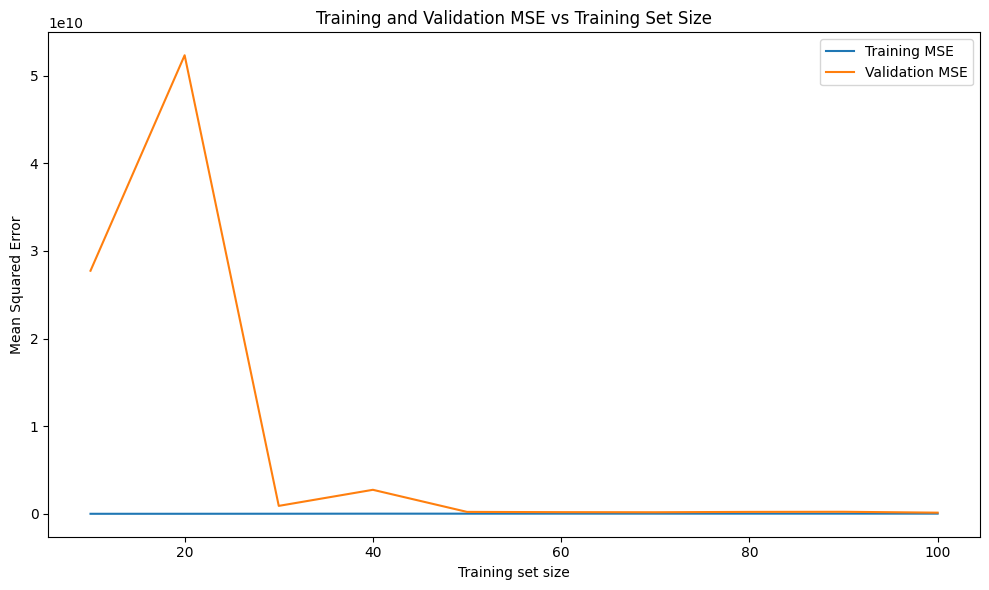

In [34]:
#WILL PROB DELETE THIS AS IT DOESNT SHOW THE TRAINING MSE TREND
fig = plt.figure(figsize=(10, 6))

plt.plot(sizes, train_mses, label = "Training MSE")
plt.plot(sizes, val_mses, label = "Validation MSE")
plt.title("Training and Validation MSE vs Training Set Size")
plt.xlabel("Training set size")
plt.ylabel("Mean Squared Error")
plt.legend()

plt.tight_layout()
plt.show()

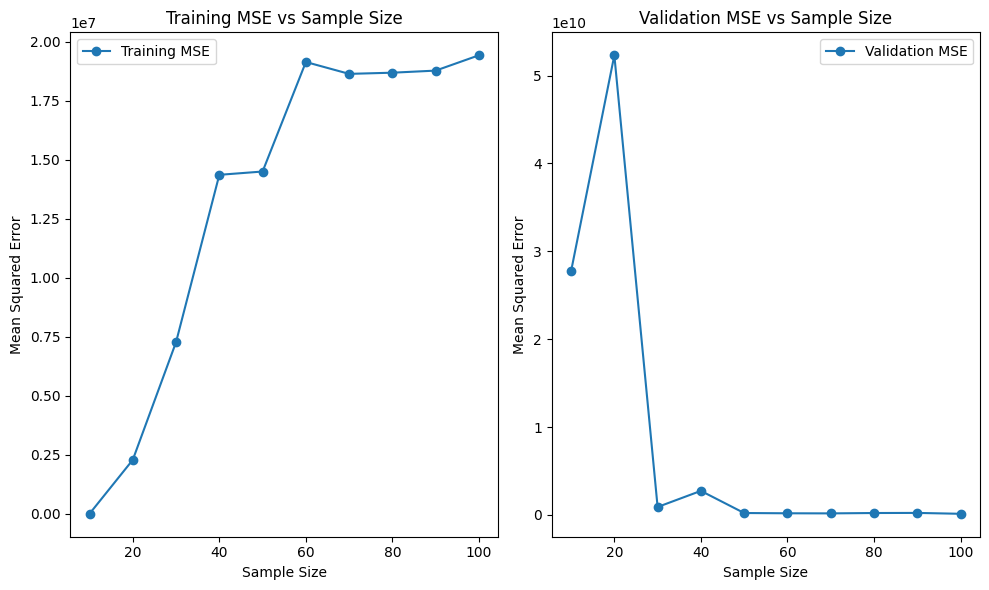

In [35]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()

## Quadratic regression - Facebook page dataset

In [36]:
qtrain_mses = []
qval_mses = []

for s in sizes:
    qtrial_tmse = []
    qtrial_vmse = []
    for n in range(ntrials):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=42)
        qmodel = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
        qmodel.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        qtrain_pred = qmodel.predict(X_train)
        qval_pred = qmodel.predict(X_val)
        
        qmse_train = mean_squared_error(y_train, qtrain_pred)
        qmse_val = mean_squared_error(y_val, qval_pred)

        qtrial_tmse.append(qmse_train)
        qtrial_vmse.append(qmse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(qtrial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(qtrial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    qtrain_mses.append(np.mean(qtrial_tmse))
    qval_mses.append(np.mean(qtrial_vmse))

Sample Size 10: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 7881651322978392.000


Sample Size 20: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 473499852872700864.000


Sample Size 30: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 29375475921310100.000


Sample Size 40: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 848880840745079936.000


Sample Size 50: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 372719976526626.562


Sample Size 60: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 30449294414128.566


Sample Size 70: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 383743174902300.250


Sample Size 80: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 518623437056419.500


Sample Size 90: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 460503526462455.438


Sa

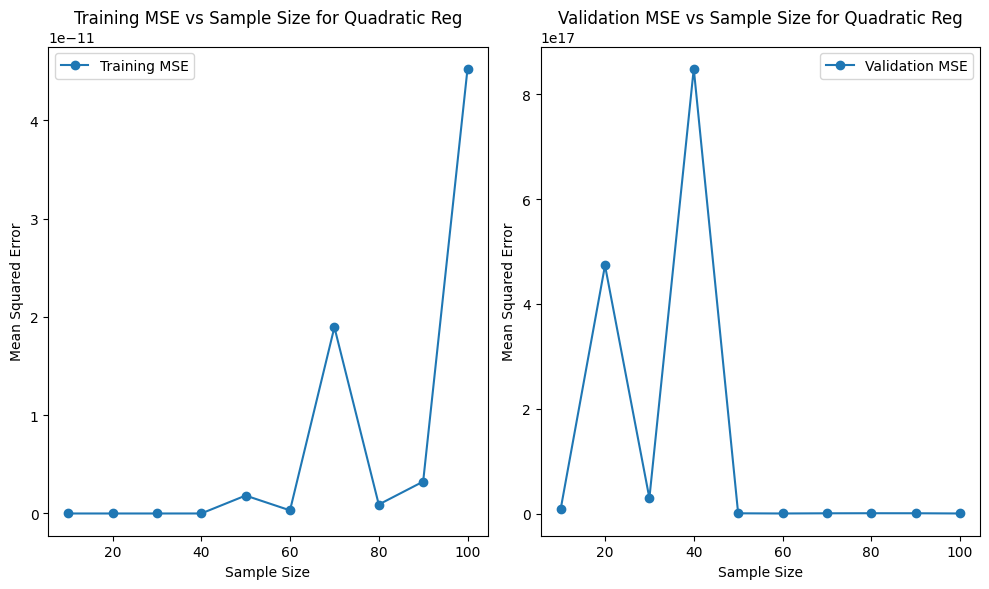

In [37]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, qtrain_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size for Quadratic Reg')
ax1.legend()

ax2.plot(sizes, qval_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size for Quadratic Reg')
ax2.legend()

plt.tight_layout()
plt.show()

## Cross-validation - Facebook page dataset

In [38]:
lscores = cross_val_score(model, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

qscores = cross_val_score(qmodel, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

lin_cv_mse = -np.mean(lscores)
quad_cv_mse = -np.mean(qscores)

print(f"Linear Regression Cross-Validation MSE: {lin_cv_mse:.3f}")
print(f"Quadratic Regression Cross-Validation MSE: {quad_cv_mse:.3f}")

Linear Regression Cross-Validation MSE: 60440451.549
Quadratic Regression Cross-Validation MSE: 111476702050.629


In [39]:
if quad_cv_mse < lin_cv_mse:
    print("Quadratic Regression is the winning model.")
else:
    print("Linear Regression is the winning model.")

Linear Regression is the winning model.


According to the cross-validation, the linear regression is a better model for the Facebook page dataset.

## Regression - News popularity in social media dataset

https://archive.ics.uci.edu/dataset/432/news+popularity+in+multiple+social+media+platforms

In [ ]:
# data preparation
# sample training sets of 10,20,30,... I WOULD MAYBE DO BIGGER SIZES BCOS OF THE DATASET SIZE

In [ ]:
# apply linear regression

In [ ]:
# calculate mse score

## Quadratic regression - News popularity on social media dataset

In [ ]:
#do the same as in regression but use logistic regression and logistic loss function

## Classification - Wine dataset

https://archive.ics.uci.edu/dataset/109/wine

## Classification - Online Retail dataset

https://archive.ics.uci.edu/dataset/352/online+retail